In [22]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"
if "ivan" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/"



INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'output')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory 
try:
    new_dir = pathlib.Path(FIG_DIR+'/snowfall_rate/')
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass




mimi.uio.no


In [23]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings


from imports import (np, plt, xr, glob, pd, cm, set_context, )


In [24]:
# reload imports
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [25]:
# plot cosmetics
set_context('paper', font_scale=1.5, rc={"lines.linewidth": 2})

In [26]:
# met_dict_p[key]  = 
ds_met_p = xr.open_mfdataset(sorted(glob(os.path.join(INPUT_DATA_DIR, 'Met-No_obs/SN87110/*sum(precipitation_amount PT1H)_2023*'))))

In [27]:
ds_geonor_p = xr.open_mfdataset(sorted(glob(os.path.join(INPUT_DATA_DIR, f'geonor/precip_*.nc'))))

In [28]:
_df = ds_met_p.sel(time=slice('2023-02-15','2023-03-16T')).to_dataframe()

In [29]:
_series = (ds_geonor_p['precipitation'].sel(time=slice('2023-02-15','2023-03-16T')).resample(time='1H').sum()).to_series()

In [30]:
df = pd.concat([_df, _series])

In [37]:
df

,sum(precipitation_amount PT1H),precipitation
time,,
2023-02-15 00:00:00,0.0,NaN
2023-02-15 01:00:00,0.0,NaN
2023-02-15 02:00:00,0.0,NaN
2023-02-15 03:00:00,0.0,NaN
2023-02-15 04:00:00,0.0,NaN
...,...,...
2023-03-16 19:00:00,NaN,0.0
2023-03-16 20:00:00,NaN,0.0
2023-03-16 21:00:00,NaN,0.0


In [41]:
df.rename(columns={"sum(precipitation_amount PT1H)":"Airport", "precipitation":"Geonor"}, inplace=True)

<Axes: xlabel='time', ylabel='precipitation (mm/h)'>

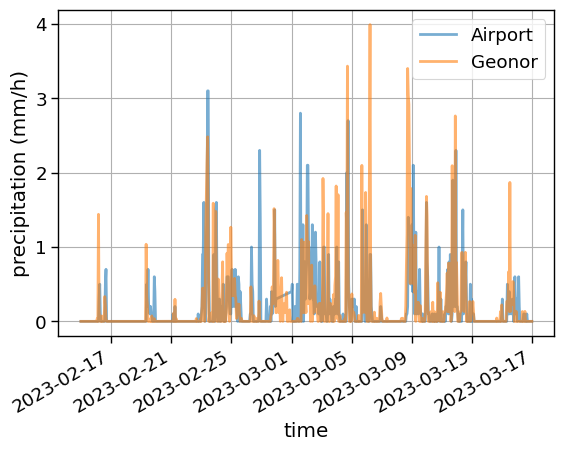

In [43]:
df.plot(grid=True, ylabel='precipitation (mm/h)', alpha=0.6)

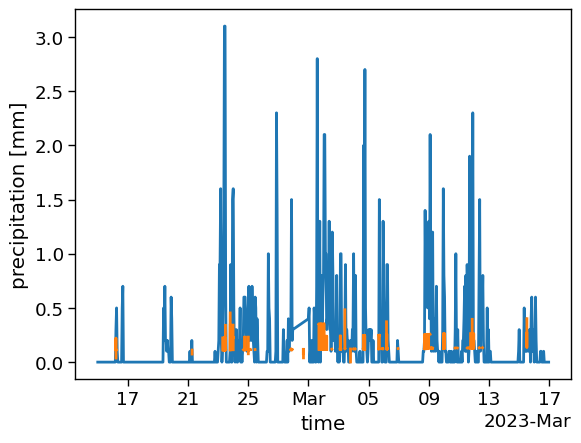

In [22]:
ds_met_p['sum(precipitation_amount PT1H)'].sel(time=slice('2023-02-15','2023-03-16T')).plot()
ds_geonor_p['precipitation'].sel(time=slice('2023-02-15','2023-03-16T')).plot()